# 02. Exploratory analysis on available training outcomes

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "src").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.config import RESULTS_DIR, ALL_MODEL_FEATURES, FORBIDDEN_COLUMNS
from src.data import load_raw_dataset, clean_and_prepare_dataset, attach_label_availability
from src.features import compute_schedule_and_calendar_features
summary = json.loads((RESULTS_DIR / "run_summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})


In [2]:
raw = load_raw_dataset()
clean, _ = clean_and_prepare_dataset(raw)
features, _ = attach_label_availability(compute_schedule_and_calendar_features(clean))
cutoff = pd.Timestamp(summary["split_manifest"]["model_fit"]["fit_available_at"])
train_end = pd.Timestamp(summary["split_manifest"]["train"]["end_date"])
train = features[(features.flight_date <= train_end) & (features.label_available_at < cutoff)]
print("Available fitting rows:", len(train), "Delay prevalence:", round(train.is_delayed.mean(), 4))
assert len(train) == summary["split_manifest"]["model_fit"]["fitted_rows"]

Available fitting rows: 227520 Delay prevalence: 0.2582


The following plots use only labels available at the final fitting cutoff. Group rates are descriptive associations. Sample sizes and shared daily disruptions limit comparisons between carriers or airports.

,mean,count
sched_dep_hour,,
5,0.105769,1352
6,0.120790,18172
7,0.119905,15504
8,0.168107,18161
9,0.175696,13973
10,0.190186,11147
11,0.190572,10988
12,0.212901,12278
13,0.252220,13286


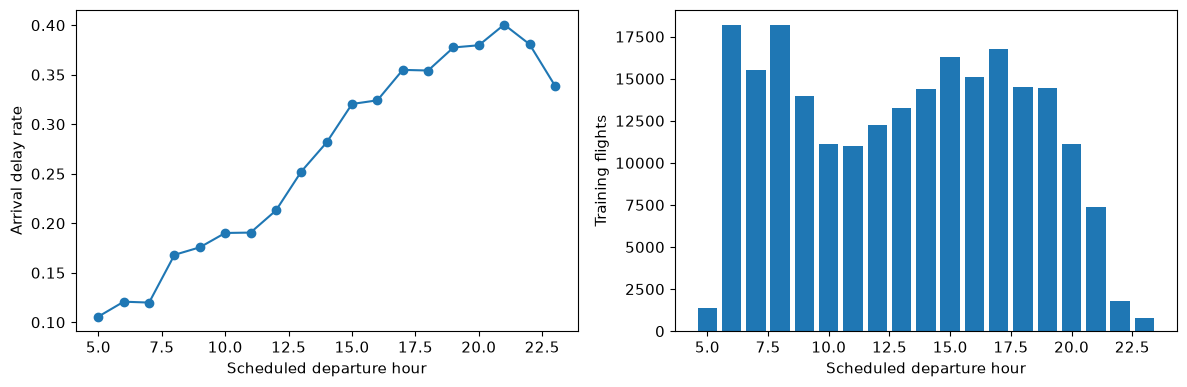

In [3]:
hour = train.groupby("sched_dep_hour").is_delayed.agg(["mean", "count"])
display(hour)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hour.index, hour["mean"], marker="o")
axes[0].set(xlabel="Scheduled departure hour", ylabel="Arrival delay rate")
axes[1].bar(hour.index, hour["count"])
axes[1].set(xlabel="Scheduled departure hour", ylabel="Training flights")
plt.tight_layout(); plt.show()

,mean,count
carrier,,
HA,0.137795,254
AS,0.163022,503
VX,0.188712,3455
AA,0.199404,22477
US,0.202763,13755
DL,0.206041,33173
UA,0.231700,40151
WN,0.244288,8228
9E,0.276216,11596


,mean,count
origin,,
LGA,0.239178,68518
JFK,0.253898,76834
EWR,0.278125,82168


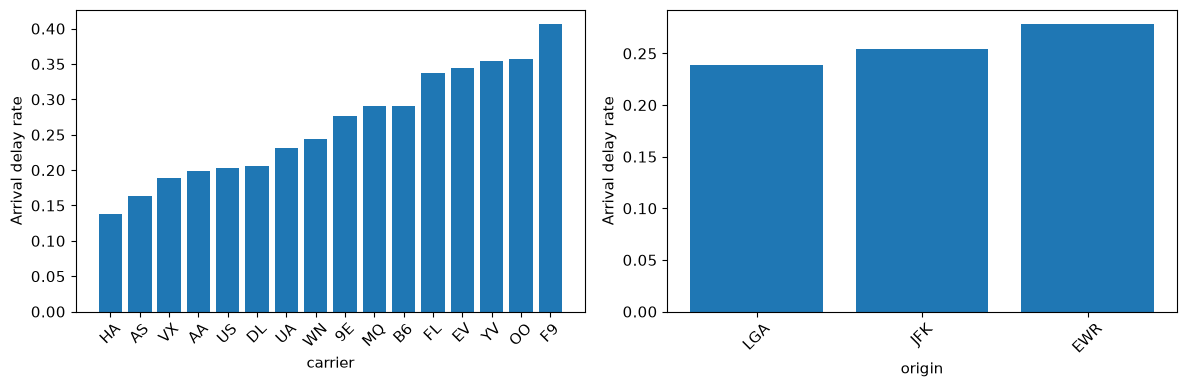

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, key in zip(axes, ["carrier", "origin"]):
    group = train.groupby(key).is_delayed.agg(["mean", "count"]).sort_values("mean")
    display(group)
    axis.bar(group.index, group["mean"])
    axis.set(xlabel=key, ylabel="Arrival delay rate")
    axis.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

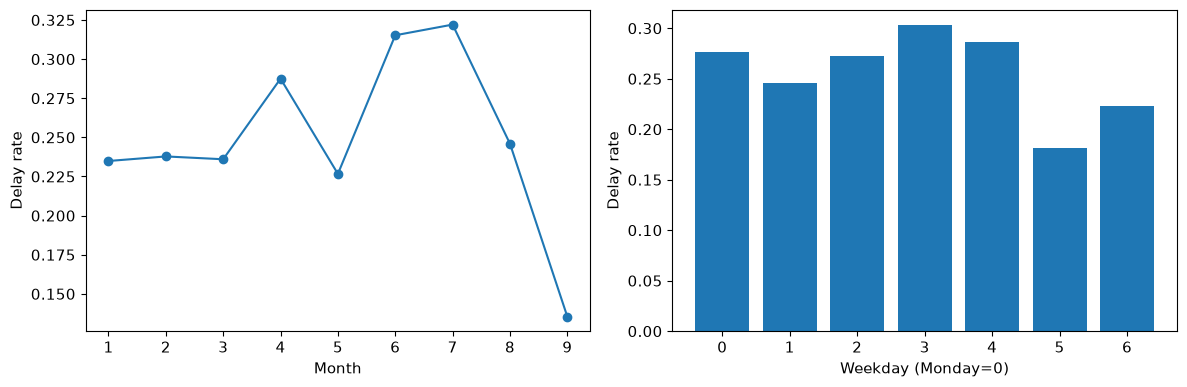

,mean,count
route,,
JFK_LAX,0.196426,7779
LGA_ATL,0.277160,7014
LGA_ORD,0.222934,5773
JFK_SFO,0.230466,5580
EWR_ORD,0.267619,4200
JFK_BOS,0.221421,4024
LGA_CLT,0.262481,3966
LGA_MIA,0.199793,3859
JFK_MCO,0.258039,3856


In [5]:
month = train.groupby("month").is_delayed.agg(["mean", "count"])
dow = train.groupby("day_of_week").is_delayed.agg(["mean", "count"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(month.index, month["mean"], marker="o"); axes[0].set(xlabel="Month", ylabel="Delay rate")
axes[1].bar(dow.index, dow["mean"]); axes[1].set(xlabel="Weekday (Monday=0)", ylabel="Delay rate")
plt.tight_layout(); plt.show()
display(train.groupby("route").is_delayed.agg(["mean", "count"]).sort_values("count", ascending=False).head(15))

The next table is a retrospective distribution-shift audit across predefined partitions. These test-label summaries are not used to choose model parameters, calibration or thresholds.

In [6]:
display(pd.DataFrame({k: summary["split_manifest"][k] for k in ["train", "validation", "test"]}).T[["start_date", "end_date", "row_count", "positive_prevalence"]])
from src.features import ScheduleContext
roster = raw.copy(); roster["flight_date"] = pd.to_datetime(roster[["year", "month", "day"]])
context = ScheduleContext.from_roster(roster)
scheduled = context.transform(compute_schedule_and_calendar_features(clean))
display(scheduled[["origin_hour_scheduled_departures", "origin_window_scheduled_departures"]].describe())
assert sum(context.counts.values()) == len(raw)
print("All raw scheduled flights contribute to demand counts, including missing outcomes.")

,start_date,end_date,row_count,positive_prevalence
train,2013-01-01,2013-09-12,228299,0.259134
validation,2013-09-13,2013-11-06,50466,0.156402
test,2013-11-07,2013-12-31,48581,0.268562


,origin_hour_scheduled_departures,origin_window_scheduled_departures
count,327346.000000,327346.000000
mean,20.502642,57.624590
std,5.929249,13.398921
min,1.000000,1.000000
25%,17.000000,50.000000
50%,21.000000,60.000000
75%,24.000000,67.000000
max,38.000000,93.000000


All raw scheduled flights contribute to demand counts, including missing outcomes.


Feature engineering follows these patterns without asserting causality: cyclic clock/calendar representations, carrier and airport identities, smoothed past outcome rates, recent released outcomes, and scheduled demand. The development ablation in notebook 03 measures their empirical contribution.